# Play dice

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import altair as alt
from matplotlib import pyplot as plt
import pandas as pd
from tqdm import tqdm

from dice.agents import Agent, SmartAgent
from dice.game import FillOrBust

# alt.renderers.set_embed_options(theme="dark")
# alt.renderers.enable("mimetype")

# Utility functions

In [3]:
def plot_training_metric(
    agent: Agent,
    metric: str = "num_turns",
    downsample: bool = True,
) -> None:
    # Format the data
    data = getattr(agent, metric)
    if downsample:
        data = data[:: len(data) // min(2500, len(data))]

    if metric == "num_turns":
        s = pd.Series(data)
        source = (
            pd.DataFrame(-s.diff()[s.diff() < 0], columns=[metric])
            .reset_index()
            .rename(columns={"index": "episode"})
        )
    else:
        source = (
            pd.DataFrame(data, columns=[metric])
            .reset_index()
            .rename(columns={"index": "episode"})
        )
    print(f"Median `{metric}` after training: {source.tail(50)[metric].median()}")

    # Create the chart
    padding = int(0.1 * len(source))
    line = (
        alt.Chart(source)
        .mark_line(color="red", size=3)
        .transform_window(
            rolling_mean=f"median({metric})",
            frame=[-padding, padding],
        )
        .encode(x="episode", y="rolling_mean:Q")
    )
    points = (
        alt.Chart(source)
        .mark_point(opacity=0.2, color="orange")
        .encode(x="episode", y=alt.Y(f"{metric}:Q").title(metric))
    )

    chart = (points + line).properties(width=400, height=250)
    chart.show()

# Train an agent

In [4]:
from train_dice_agents import main

In [10]:
trained_agents = main(
    n_episodes = 1000,
    start_learning_rate = 0.01,
    final_lr = 0.0001,
    start_epsilon = 0.8,
    final_epsilon = 0.1,
    discount_factor = 0.9,
)

100%|██████████| 1000/1000 [00:03<00:00, 273.08it/s]

Median `num_turns` after training: 28.0


alt.LayerChart(...)

In [ ]:
trained_agents = main(n_episodes=2_000)

100%|██████████| 2000/2000 [00:04<00:00, 435.06it/s]

Median `num_turns` after training: 17.0


alt.LayerChart(...)

In [12]:
smart: SmartAgent = trained_agents[0]

In [13]:
sorted(smart.q_values.items(), key=lambda x: max(x[1].values()) if len(x[1]) else 0, reverse=True)

[(Observation(last_action='hold', hold_score=1500, dice=DiceCounts(one=0, two=0, three=0, four=0, five=0, six=0)),
  defaultdict(float,
              {('roll', 0): 0.0, ('stop', None): 0.0004923456160688631})),
 (Observation(last_action='hold', hold_score=450, dice=DiceCounts(one=0, two=0, three=0, four=0, five=0, six=0)),
  defaultdict(float,
              {('stop', None): 0.00011710609990926053, ('roll', 0): 0.0})),
 (Observation(last_action='hold', hold_score=300, dice=DiceCounts(one=0, two=0, three=1, four=1, five=0, six=0)),
  defaultdict(float,
              {('roll', 2): 5.044591868973797e-10,
               ('stop', None): 0.00010408059997958731})),
 (Observation(last_action='hold', hold_score=400, dice=DiceCounts(one=0, two=0, three=0, four=1, five=0, six=0)),
  defaultdict(float,
              {('stop', None): 9.199481432897722e-05,
               ('roll', 1): 2.803857214645459e-10})),
 (Observation(last_action='hold', hold_score=350, dice=DiceCounts(one=0, two=1, three=0, fo

In [14]:
list(smart.q_values.values())[0]

defaultdict(float, {('draw', None): 7.937055799618133e-13})

In [8]:
trained_agents = main(n_episodes=10_000)

100%|██████████| 10000/10000 [00:09<00:00, 1045.89it/s]

Median `num_turns` after training: 11.0


alt.LayerChart(...)

In [6]:
# hyperparameters
n_episodes = 1000
start_learning_rate = 0.001
lr_decay = start_learning_rate / (n_episodes // 2)
final_lr = 0.0001
start_epsilon = 1.0
epsilon_decay = start_epsilon / (n_episodes // 1.5)
final_epsilon = 0.1
discount_factor = 0.5

# agent = Agent("dumb")
# agent = StopAtNDiceAgent("stop_at_n", 5)
agent = SmartAgent(
    "smart",
    initial_learning_rate=start_learning_rate,
    learning_rate_decay=lr_decay,
    final_learning_rate=final_lr,
    initial_epsilon=start_epsilon,
    epsilon_decay=epsilon_decay,
    final_epsilon=final_epsilon,
    discount_factor=discount_factor,
)

env = FillOrBust([agent])
for episode in tqdm(range(n_episodes)):
    obs, info = env.reset_for_new_game()
    done = False

    # play one episode
    while not done:
        action = agent.get_action(obs)
        next_obs, reward, terminated, truncated, info = env.step(action)

        # update the agent
        agent.update(obs, action, reward, terminated, next_obs)

        # update if the environment is done and the current obs
        done = terminated or truncated
        obs = next_obs

    agent.decay_epsilon()
    agent.decay_learning_rate()

num_states = len(agent.q_values)
model_size = sys.getsizeof(agent.q_values) / 1024**2  # Size in MB
print(
    f"Done training!\nObserved states: {num_states}\nModel size: {model_size:0.2f} MB"
)

  0%|          | 0/1000 [00:00<?, ?it/s]


ValueError: too many values to unpack (expected 2)

In [56]:
plot_training_metric(env, metric="num_turns_to_win")

Median `num_turns_to_win` after training: 46.0


alt.LayerChart(...)

In [26]:
plot_training_metric(env, metric="num_turns_to_win")

Median `num_turns_to_win` after training: 41.5


alt.LayerChart(...)

<Axes: >

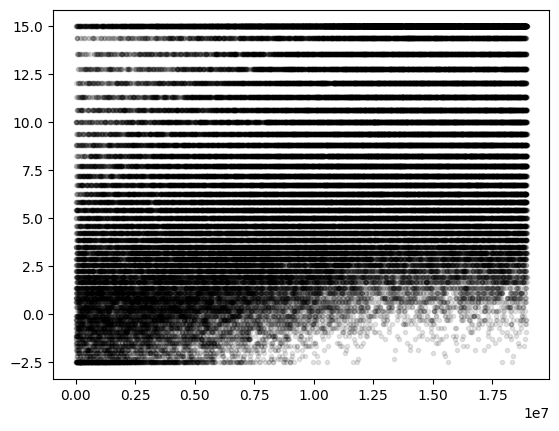

In [27]:
pd.Series(env.rewards).where(lambda x: x != 0).dropna(how="all").plot(
    style="k.", alpha=0.1
)

In [37]:
def sort_q_values(q):
    return {
        (
            obs.hold_score,
            obs.num_held_dice,
            f"{obs.card.category}_{obs.card.bonus}" if obs.card else "",
        ): {
            key[0]: round(10000 * q[obs][key], 2)
            for key in sorted(q[obs].keys(), key=q[obs].get, reverse=True)
        }
        for obs in sorted(
            q.keys(),
            key=lambda o: sum(q[o].values()),
            # key=lambda o: o.hold_score,
            reverse=True,
        )
        if not any(action[0] == "hold" for action in q[obs].keys())
    }

In [53]:
q = sort_q_values(agent.q_values)

In [54]:
{key: val for key, val in q.items() if key[2] == "must_bust_0"}

{(750, 5, 'must_bust_0'): {'roll': 2849.26},
 (1150, 5, 'must_bust_0'): {'roll': 2739.53},
 (500, 5, 'must_bust_0'): {'roll': 2401.88},
 (700, 5, 'must_bust_0'): {'roll': 2180.51},
 (2250, 5, 'must_bust_0'): {'roll': 2150.87},
 (400, 5, 'must_bust_0'): {'roll': 2140.96},
 (450, 5, 'must_bust_0'): {'roll': 2024.61},
 (1800, 4, 'must_bust_0'): {'roll': 1969.76},
 (2400, 5, 'must_bust_0'): {'roll': 1954.51},
 (250, 5, 'must_bust_0'): {'roll': 1642.1},
 (700, 4, 'must_bust_0'): {'roll': 1498.24},
 (1300, 4, 'must_bust_0'): {'roll': 1407.3},
 (350, 5, 'must_bust_0'): {'roll': 1400.88},
 (1200, 5, 'must_bust_0'): {'roll': 1386.86},
 (1750, 5, 'must_bust_0'): {'roll': 1374.78},
 (2200, 5, 'must_bust_0'): {'roll': 1347.62},
 (5100, 5, 'must_bust_0'): {'roll': 1325.31},
 (550, 5, 'must_bust_0'): {'roll': 1307.89},
 (1800, 3, 'must_bust_0'): {'roll': 1250.4},
 (600, 5, 'must_bust_0'): {'roll': 1236.36},
 (2000, 5, 'must_bust_0'): {'roll': 1209.89},
 (2200, 4, 'must_bust_0'): {'roll': 1197.99},
 

<Axes: >

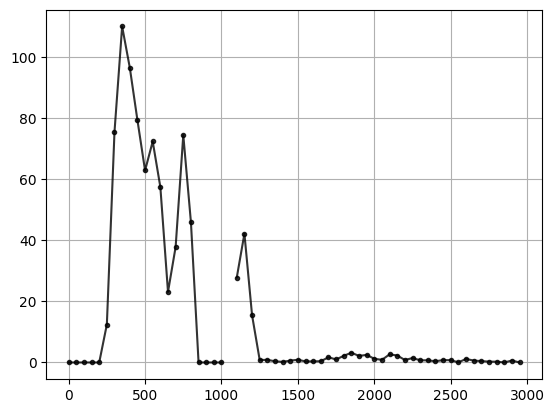

In [34]:
action = "roll"
num_held_dice = 5
card = "garden_variety_500"
stop_values = []
scores = list(range(0, 3000, 50))
for score in scores:
    stop_values.append(q.get((score, num_held_dice, card), {action: 0.0}).get(action))
s = pd.Series(stop_values, index=scores)
s.plot(style="k.-", grid=True, alpha=0.8)

In [24]:
{
    key: val
    for key, val in q.items()
    if "roll" in val and "stop" in val and val.get("roll", 0) > val.get("stop", 0)
}

{(300, 5, 'garden_variety_500'): {'roll': 2.46, 'stop': -0.68},
 (250, 5, 'garden_variety_300'): {'roll': 0.3, 'stop': 0.18},
 (2150, 4, 'garden_variety_300'): {'roll': 0.25, 'stop': 0.08},
 (1500, 2, 'garden_variety_500'): {'roll': 0.13, 'stop': 0.04},
 (1950, 5, 'garden_variety_400'): {'roll': 0.13, 'stop': 0.02},
 (2300, 5, 'garden_variety_300'): {'roll': 0.12, 'stop': 0.02},
 (1750, 4, 'garden_variety_500'): {'roll': 0.12, 'stop': 0.01},
 (1700, 4, 'garden_variety_300'): {'roll': 0.09, 'stop': 0.04},
 (1400, 3, 'garden_variety_300'): {'roll': 0.08, 'stop': 0.04},
 (1100, 3, 'garden_variety_400'): {'roll': 0.1, 'stop': 0.01},
 (2350, 4, 'garden_variety_300'): {'roll': 0.07, 'stop': 0.04},
 (1850, 5, 'garden_variety_400'): {'roll': 0.08, 'stop': 0.02},
 (2950, 4, 'garden_variety_300'): {'roll': 0.07, 'stop': 0.03},
 (1950, 4, 'garden_variety_400'): {'roll': 0.06, 'stop': 0.04},
 (2300, 3, 'garden_variety_500'): {'roll': 0.06, 'stop': 0.04},
 (1900, 4, 'garden_variety_300'): {'roll': 

In [46]:
plot_training_metric(env, metric="turn_scores")

Median `turn_scores` after training: 150.0


alt.LayerChart(...)

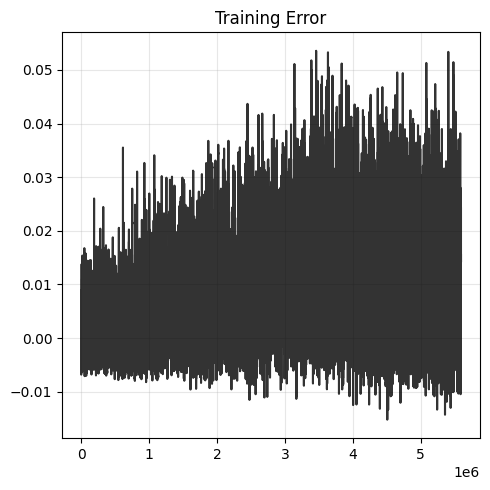

In [47]:
rolling_length = 1000
fig, ax = plt.subplots(ncols=1, figsize=(5, 5))
ax.set_title("Training Error")
training_error_moving_average = (
    np.convolve(np.array(agent.training_error), np.ones(rolling_length), mode="same")
    / rolling_length
)
ax.plot(
    range(len(training_error_moving_average)),
    training_error_moving_average,
    color="black",
    alpha=0.8,
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()